# Task 1.3 – Sentence embeddings with Transformer models
Christos Palantzidis · D7041E Lab 2

Three pre-trained Sentence-Transformer models embed 9 sentences; we plot the all-vs-all
cosine similarity as a 3D bar graph (one per model). Run all cells (≈ 3–5 minutes).

In [1]:
# Install the sentence-transformers library (it also installs PyTorch and HuggingFace tools).
%pip install -q sentence-transformers matplotlib

In [2]:
# Import the Colab helper that connects this notebook to Google Drive.
from google.colab import drive
# Import Path to build file paths.
from pathlib import Path
# Import NumPy for vector maths.
import numpy as np
# Import matplotlib to draw the plots.
import matplotlib.pyplot as plt
# Import the class that loads a pre-trained sentence-embedding model.
from sentence_transformers import SentenceTransformer

# Connect Google Drive so the figures can be saved there.
drive.mount("/content/drive")
# The Drive folder where the results are saved.
drive_folder = Path("/content/drive/MyDrive/Lab2 advanced AI")

# The 9 sentences of the task: 3 about animals, 3 about programming, 3 about food.
SENTENCES = [
    "The cat sat on the mat and purred",
    "A kitten is sleeping on a soft rug",
    "Dogs love to play fetch in the park",
    "Python is a popular programming language",
    "JavaScript runs in web browsers",
    "Writing code requires logical thinking",
    "Italian pizza with fresh mozzarella",
    "Cooking pasta requires boiling water",
    "The recipe calls for olive oil and garlic",
]
# The three Transformer embedders of the task (names on HuggingFace).
MODELS = [
    "sentence-transformers/all-MiniLM-L6-v2",
    "sentence-transformers/all-mpnet-base-v2",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
]

Mounted at /content/drive


In [3]:
# Compute the all-vs-all cosine similarity matrix of a set of embeddings.
def cosine_matrix(emb):
    # Divide every row (sentence vector) by its length, so every vector has length 1.
    emb = emb / np.linalg.norm(emb, axis=1, keepdims=True)
    # For unit vectors the dot product equals the cosine similarity: 9 x 9 matrix.
    return emb @ emb.T


# Dictionary model name -> 9 x 9 similarity matrix.
sims = {}
# Process the three models one after the other.
for name in MODELS:
    # Download (first time only) and load the pre-trained model.
    model = SentenceTransformer(name)
    # Turn each sentence into one embedding vector: result is a 9 x dim array.
    emb = model.encode(SENTENCES)
    # Compute and store the similarity matrix of this model.
    sims[name] = cosine_matrix(emb)
    # Print the size of the embeddings (384 or 768).
    print(f"{name}: embedding dimension = {emb.shape[1]}")
    # Print the similarity matrix rounded to 2 decimals.
    print(np.round(sims[name], 2))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (32 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2: embedding dimension = 384
[[ 1.    0.68  0.02  0.19 -0.09  0.1   0.03 -0.04 -0.11]
 [ 0.68  1.   -0.05  0.26 -0.05  0.13  0.07 -0.09 -0.12]
 [ 0.02 -0.05  1.    0.07  0.13 -0.09 -0.07 -0.08 -0.02]
 [ 0.19  0.26  0.07  1.    0.03  0.28  0.15  0.11  0.06]
 [-0.09 -0.05  0.13  0.03  1.   -0.04  0.11 -0.06 -0.11]
 [ 0.1   0.13 -0.09  0.28 -0.04  1.    0.06  0.19  0.05]
 [ 0.03  0.07 -0.07  0.15  0.11  0.06  1.    0.34  0.46]
 [-0.04 -0.09 -0.08  0.11 -0.06  0.19  0.34  1.    0.36]
 [-0.11 -0.12 -0.02  0.06 -0.11  0.05  0.46  0.36  1.  ]]


/tmp/ipykernel_2258/973625335.py:40: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


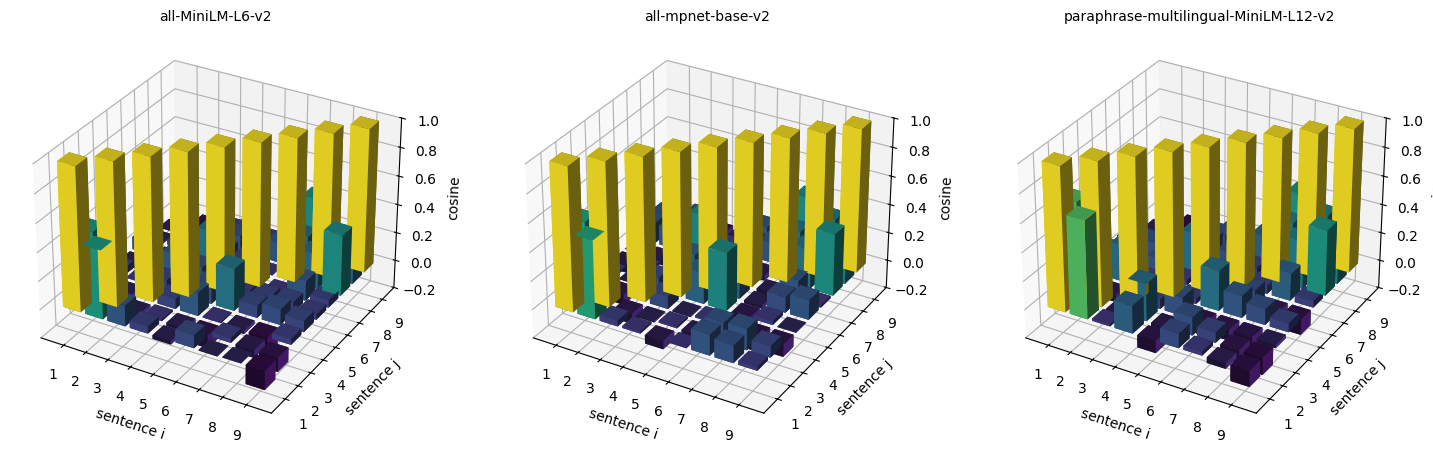

In [4]:
# Lowest value of the common colour/height scale (negative cosines go down to about -0.13 here).
VMIN = -0.2


# Draw one 3D bar graph of a 9 x 9 similarity matrix on the given axes.
def plot_3d_similarity(ax, sim, title):
    # Number of sentences (9).
    n = sim.shape[0]
    # Grid with the (i, j) coordinates of every sentence pair.
    xs, ys = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    # Flatten the grid and the similarities into 81 values each.
    xs, ys, zs = xs.ravel(), ys.ravel(), sim.ravel()
    # Same colour scale for every model: cosine -0.2 = dark, 1.0 = yellow.
    color_scale = plt.Normalize(vmin=VMIN, vmax=1.0)
    # Colour every bar by its height on that common scale.
    colors = plt.cm.viridis(color_scale(zs))
    # Draw 81 bars: position (i, j), width 0.8, height = cosine similarity.
    ax.bar3d(xs - 0.4, ys - 0.4, np.zeros_like(zs), 0.8, 0.8, zs, color=colors, shade=True)
    # Label the x-axis ticks with the sentence numbers 1..9.
    ax.set_xticks(range(n)); ax.set_xticklabels([str(i + 1) for i in range(n)])
    # Label the y-axis ticks with the sentence numbers 1..9.
    ax.set_yticks(range(n)); ax.set_yticklabels([str(i + 1) for i in range(n)])
    # Axis titles.
    ax.set_xlabel("sentence i"); ax.set_ylabel("sentence j"); ax.set_zlabel("cosine")
    # Same vertical scale for all three plots, so heights can be compared between models.
    ax.set_zlim(VMIN, 1.0)
    # Title of this plot (the model name).
    ax.set_title(title, fontsize=10)


# Create a wide figure for three plots.
fig = plt.figure(figsize=(18, 6))
# One 3D plot per model.
for k, name in enumerate(MODELS):
    # Add a 3D sub-plot in position k+1 of a 1 x 3 grid.
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    # Draw the 3D bars of this model.
    plot_3d_similarity(ax, sims[name], name.split("/")[-1])
# Avoid overlapping labels.
plt.tight_layout()
# Save the figure in the Drive folder.
plt.savefig(drive_folder / "task1_3_similarity_3d.png", dpi=150)
# Display the figure.
plt.show()

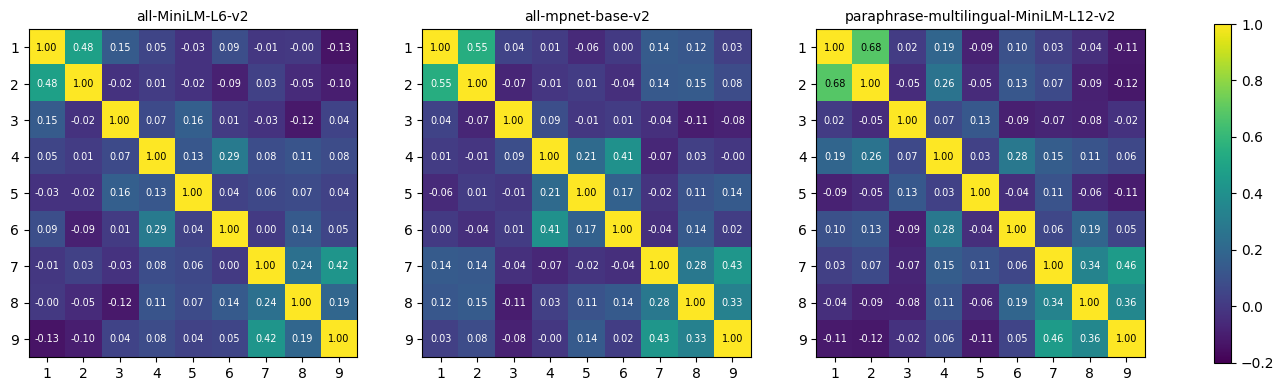

In [5]:
# Second figure: the same matrices as 2D heat maps with the numbers written in the cells.
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
# One heat map per model.
for ax, name in zip(axes, MODELS):
    # Draw the 9 x 9 matrix as coloured squares on the common scale (-0.2 = dark, 1 = yellow).
    im = ax.imshow(sims[name], vmin=VMIN, vmax=1.0, cmap="viridis")
    # Loop over the rows.
    for i in range(len(SENTENCES)):
        # Loop over the columns.
        for j in range(len(SENTENCES)):
            # Write the value in the cell (white on dark squares, black on light ones).
            ax.text(j, i, f"{sims[name][i, j]:.2f}", ha="center", va="center",
                    color="white" if sims[name][i, j] < 0.6 else "black", fontsize=7)
    # Number the columns 1..9.
    ax.set_xticks(range(9)); ax.set_xticklabels(range(1, 10))
    # Number the rows 1..9.
    ax.set_yticks(range(9)); ax.set_yticklabels(range(1, 10))
    # Title = model name.
    ax.set_title(name.split("/")[-1], fontsize=10)
# One colour bar for all three heat maps.
fig.colorbar(im, ax=axes, shrink=0.8)
# Save the figure in the Drive folder.
plt.savefig(drive_folder / "task1_3_similarity_heatmaps.png", dpi=150)
# Display the figure.
plt.show()

In [6]:
# Topic of every sentence: 0 = animals, 1 = programming, 2 = food.
topic = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
# True for pairs of DIFFERENT sentences with the SAME topic.
same = (topic[:, None] == topic[None, :]) & ~np.eye(9, dtype=bool)
# True for pairs of sentences with DIFFERENT topics.
diff = topic[:, None] != topic[None, :]
# Compare the models with one number each.
for name in MODELS:
    # Similarity matrix of this model.
    s = sims[name]
    # Mean similarity inside topics, between topics, and their difference ("gap").
    print(f"{name.split('/')[-1]:40s} within-topic mean = {s[same].mean():.3f}   "
          f"between-topic mean = {s[diff].mean():.3f}   gap = {s[same].mean() - s[diff].mean():.3f}")

all-MiniLM-L6-v2                         within-topic mean = 0.213   between-topic mean = 0.019   gap = 0.194
all-mpnet-base-v2                        within-topic mean = 0.261   between-topic mean = 0.028   gap = 0.233
paraphrase-multilingual-MiniLM-L12-v2    within-topic mean = 0.231   between-topic mean = 0.028   gap = 0.203
